Grid index loaded:
  file: /home/users/jianxing/New_final/ACI_gridpoint_index.csv
  n_rows: 404
  cluster column: cluster
  lat_dir column: lat_dir
  lon_dir column: lon_dir
  latitude column: lat
  longitude column: lon
  latitude range: 15.62 46.88
  longitude range: 70.31 139.69
  clusters: ['1', '5', '7']

filtered index loaded:
  file: /gws/ssde/j25a/acure/lregayre/constraint/indices_used_to_filter_898610_members_sample_for_prim_so4_diam.dat
  n_index: 898610
  min index: 0
  max index: 999999

optimal index loaded:
  file: /home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat
  n_index: 5000
  min index: 405
  max index: 999775



Processing CSV N96 gridpoints:   0%|          | 0/404 [00:00<?, ?it/s]


Processing summary:
  CSV rows: 404
  GPE files found: 404
  GPE files missing: 0
  successfully processed: 404
  finite full: 404
  finite filtered: 404
  finite optimal: 404
  full > 3 W m^-2: 395

Saved:
  CSV: /home/users/jianxing/New_final/land/Figure2_style/FACI_uncertainty_China_land/FACI_uncertainty_China_land_ann_gridpoint_summary_direct_csv_points.csv
  NPZ: /home/users/jianxing/New_final/land/Figure2_style/FACI_uncertainty_China_land/FACI_uncertainty_China_land_ann_direct_csv_points.npz



,row_id,cluster,latitude,longitude,lat_dir,lon_dir,constraint_text,expected_file,file_found,mean_file,...,mean_optimal,p5_full,p95_full,p5_filtered,p95_filtered,p5_optimal,p95_optimal,n_full,n_filtered,n_optimal
0,0,1,15.62,107.81,lat_15.62,lon_107.81,ann_ACI_c1_lat_15.62_lon_107.81,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,1.277211,-3.090174,8.747638,-3.221821,6.271215,-2.233224,4.584756,1000000,898610,5000
1,1,1,15.62,120.94,lat_15.62,lon_120.94,ann_ACI_c1_lat_15.62_lon_120.94,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,0.156987,-1.320150,4.386346,-1.365558,2.013073,-1.058195,1.359651,1000000,898610,5000
2,2,1,16.88,105.94,lat_16.88,lon_105.94,ann_ACI_c1_lat_16.88_lon_105.94,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,1.838889,-4.014280,12.545672,-4.194226,9.070420,-3.069375,6.650356,1000000,898610,5000
3,3,1,18.12,83.44,lat_18.12,lon_83.44,ann_ACI_c1_lat_18.12_lon_83.44,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,-0.633766,-2.312841,2.700373,-2.366496,1.712585,-1.929169,0.719221,1000000,898610,5000
4,4,1,18.12,94.69,lat_18.12,lon_94.69,ann_ACI_c1_lat_18.12_lon_94.69,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,-1.166872,-2.901153,1.271341,-2.962877,1.119821,-2.565010,0.267177,1000000,898610,5000


Plotting summary:
  valid gridpoints before full>3 filter: 404
  valid gridpoints after full>3.0 filter: 395
  longitude range: 74.06 139.69
  latitude range: 15.62 46.88
  full uncertainty range: 3.006929134451658 35.647923055848246
  filtered uncertainty range: 2.528796884845608 35.76736699994505
  optimal uncertainty range: 1.8505365918138703 30.050211192245705
  remaining pct range: 29.971025600543584 94.62229788714048



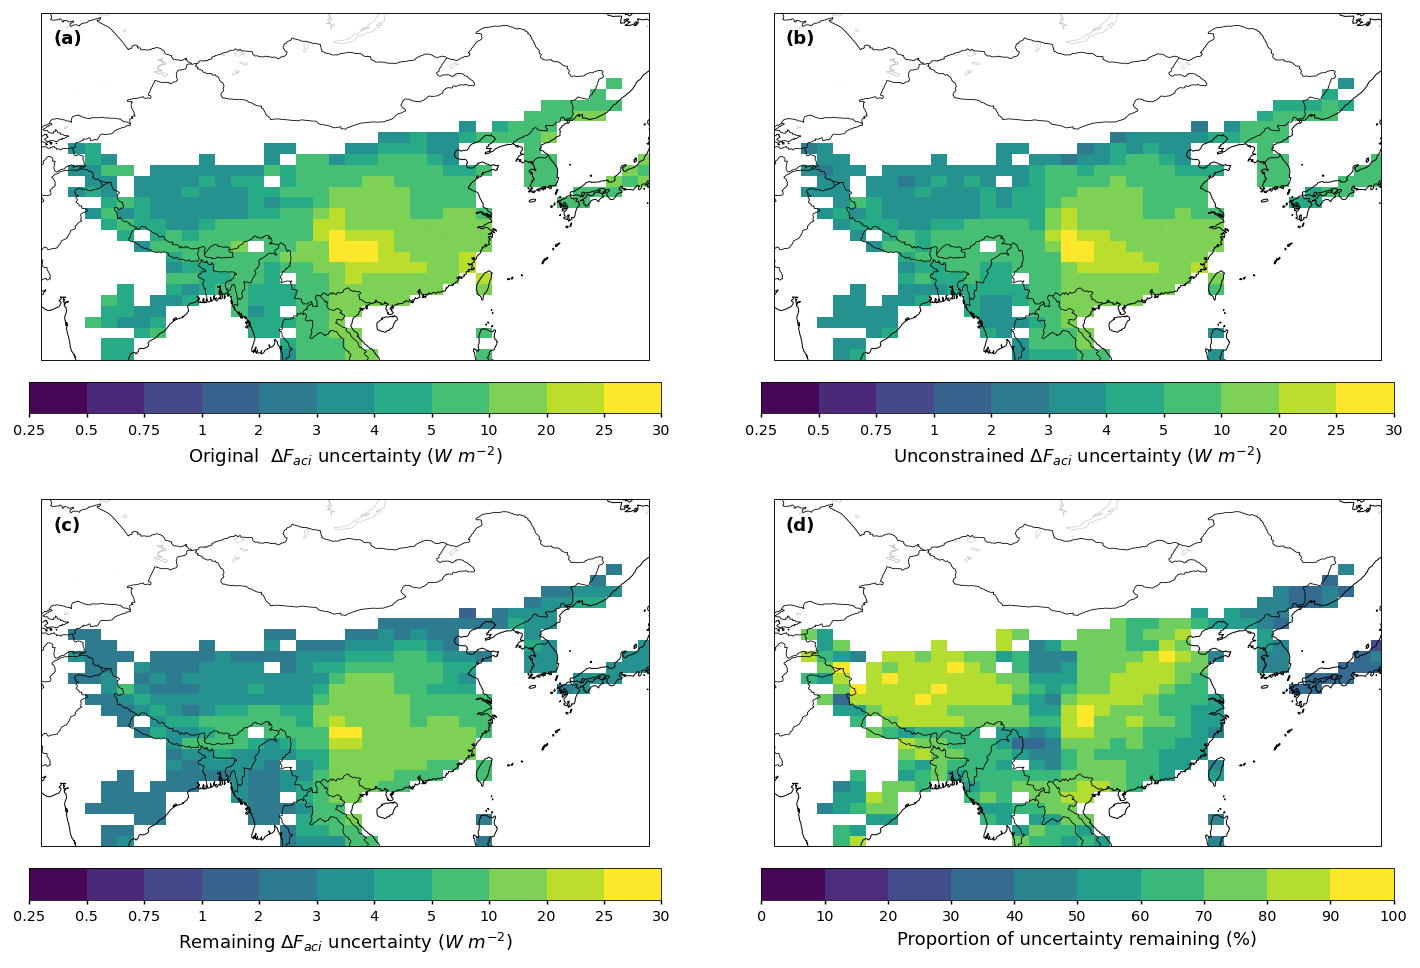

In [7]:
# ============================================================
# FACI uncertainty over China land N96 gridpoints
#
# Index usage:
#   完全学习你给的程序：
#       indices_decimal = np.loadtxt(index_file)
#       indices = np.array([int(i) for i in indices_decimal], dtype=int)
#   不减 1
#   不自动判断 R/Python index
#
# Plot style:
#   不使用等值线，不插值
#   直接使用 CSV 中的 N96 latitude / longitude
#   每个格点画成一个 square marker
#   风格接近 cluster map / Fig.2-style map
#
# Important:
#   只展示 full case uncertainty > 3 W m^-2 的格点
#   这对应 Fig.2 中 proportion remaining panel 对 original uncertainty < 3 的 mask 逻辑
#
# Output:
#   1. Notebook 直接显示图，不保存图片
#   2. 保存 summary CSV
#   3. 保存 NPZ
# ============================================================

import os
import glob
import warnings

import numpy as np
import pandas as pd

import matplotlib as mp
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

import cartopy.crs as ccrs
import cartopy.feature as cfeature

try:
    from tqdm.notebook import tqdm
except Exception:
    from tqdm import tqdm


# ============================================================
# 1. 基础路径设置
# ============================================================

gpe_output_dir = "/gws/ssde/j25a/acure/jianxing/aci/emulation/data_post_emulation"

grid_index_file = "/home/users/jianxing/New_final/ACI_gridpoint_index.csv"

sample_file_norm_all = "/home/users/lregayre/R/ACURE/samples/constrained_multi_million_sample_first_million.dat"

filtered_indices_file = "/gws/ssde/j25a/acure/lregayre/constraint/indices_used_to_filter_898610_members_sample_for_prim_so4_diam.dat"

optimal_indices_file = "/home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat"

out_dir = "/home/users/jianxing/New_final/land/Figure2_style/FACI_uncertainty_China_land"
os.makedirs(out_dir, exist_ok=True)

target_month = "ann"
sample_size_full = 1000000
pred_length_text = "1000000"

china_extent = [70, 140, 15, 55]

# 明确体现 Fig.2 里的 original uncertainty > 3 W m^-2 条件
full_uncertainty_threshold = 3.0


# ============================================================
# 2. 工具函数
# ============================================================

def detect_column(df, candidates, required=True):
    lower_to_original = {c.lower(): c for c in df.columns}

    for c in candidates:
        if c.lower() in lower_to_original:
            return lower_to_original[c.lower()]

    if required:
        raise ValueError(
            f"Cannot find any of columns {candidates}. "
            f"Available columns are: {list(df.columns)}"
        )

    return None


def format_cluster_for_filename(x):
    """
    文件名里需要 ACI_c1 / ACI_c5 / ACI_c7，
    不是 ACI_c1.0。
    """
    try:
        return str(int(float(x)))
    except Exception:
        return str(x).strip()


def read_grid_index_csv(grid_index_file):
    """
    只读取 CSV 中的信息。
    不转换经纬度，不排序，不重新筛选。
    """
    df = pd.read_csv(grid_index_file)

    cluster_col = detect_column(df, ["cluster"], required=True)
    lat_dir_col = detect_column(df, ["lat_dir"], required=True)
    lon_dir_col = detect_column(df, ["lon_dir"], required=True)
    lat_col = detect_column(df, ["latitude", "lat", "grid_latitude"], required=True)
    lon_col = detect_column(df, ["longitude", "lon", "grid_longitude"], required=True)

    df["_cluster_str"] = df[cluster_col].apply(format_cluster_for_filename)
    df["_lat_dir_use"] = df[lat_dir_col].astype(str).str.strip()
    df["_lon_dir_use"] = df[lon_dir_col].astype(str).str.strip()
    df["_latitude_use"] = df[lat_col].astype(float)
    df["_longitude_use"] = df[lon_col].astype(float)

    print("Grid index loaded:")
    print("  file:", grid_index_file)
    print("  n_rows:", len(df))
    print("  cluster column:", cluster_col)
    print("  lat_dir column:", lat_dir_col)
    print("  lon_dir column:", lon_dir_col)
    print("  latitude column:", lat_col)
    print("  longitude column:", lon_col)
    print("  latitude range:", df["_latitude_use"].min(), df["_latitude_use"].max())
    print("  longitude range:", df["_longitude_use"].min(), df["_longitude_use"].max())
    print("  clusters:", sorted(df["_cluster_str"].unique().tolist()))
    print("")

    return df


def read_indices_like_your_example(index_file, label):
    """
    完全学习你给的程序：

        indices_decimal = np.loadtxt(index_file)
        indices = [int(i) for i in indices_decimal]

    不减 1。
    不自动判断。
    """
    try:
        indices_decimal = np.loadtxt(index_file)
        indices = np.array([int(i) for i in np.ravel(indices_decimal)], dtype=int)

        print(f"{label} index loaded:")
        print(f"  file:", index_file)
        print(f"  n_index:", len(indices))
        print(f"  min index:", indices.min())
        print(f"  max index:", indices.max())
        print("")

        return indices

    except Exception as e:
        raise RuntimeError(f"Failed to load {label} indices from {index_file}: {e}")


def find_gpe_mean_file(constraint_text):
    """
    匹配你的 R 输出命名规则：

    emulated_mean_values_{constraint_text}_1000000_w_o_carb.dat
    """
    exact_file = os.path.join(
        gpe_output_dir,
        f"emulated_mean_values_{constraint_text}_{pred_length_text}_w_o_carb.dat"
    )

    if os.path.exists(exact_file):
        return exact_file, exact_file

    pattern = os.path.join(
        gpe_output_dir,
        f"emulated_mean_values_{constraint_text}_*_w_o_carb.dat"
    )

    matches = sorted(glob.glob(pattern))

    if len(matches) > 0:
        return matches[0], exact_file

    return None, exact_file


def calc_ci90_stats(values, indices=None):
    """
    计算 90% CI width:
        P95 - P5
    """
    values = np.asarray(values, dtype=float)

    if indices is None:
        data = values[:sample_size_full]
    else:
        indices = np.asarray(indices, dtype=int)

        # 这里不改 index，只检查是否越界
        if indices.min() < 0 or indices.max() >= len(values):
            raise IndexError(
                f"indices out of range for values length {len(values)}. "
                f"indices min/max = {indices.min()} / {indices.max()}"
            )

        data = values[indices]

    data = data[np.isfinite(data)]

    if len(data) == 0:
        return {
            "n": 0,
            "mean": np.nan,
            "p5": np.nan,
            "p95": np.nan,
            "ci90": np.nan,
        }

    p5, p95 = np.percentile(data, [5, 95])

    return {
        "n": int(len(data)),
        "mean": float(np.mean(data)),
        "p5": float(p5),
        "p95": float(p95),
        "ci90": float(p95 - p5),
    }


# ============================================================
# 3. 读取 CSV 和 index
# ============================================================

grid_df = read_grid_index_csv(grid_index_file)

filtered_indices = read_indices_like_your_example(
    filtered_indices_file,
    label="filtered"
)

optimal_indices = read_indices_like_your_example(
    optimal_indices_file,
    label="optimal"
)


# ============================================================
# 4. 逐个 CSV 格点读取 GPE 输出并计算 CI
# ============================================================

records = []

n_file_found = 0
n_file_missing = 0
n_processed = 0

for row_id, row in tqdm(
    grid_df.iterrows(),
    total=len(grid_df),
    desc="Processing CSV N96 gridpoints"
):
    cluster_str = row["_cluster_str"]
    lat_dir = row["_lat_dir_use"]
    lon_dir = row["_lon_dir_use"]

    latitude = float(row["_latitude_use"])
    longitude = float(row["_longitude_use"])

    constraint_text = f"{target_month}_ACI_c{cluster_str}_{lat_dir}_{lon_dir}"

    mean_file, expected_file = find_gpe_mean_file(constraint_text)

    base_record = {
        "row_id": row_id,
        "cluster": cluster_str,
        "latitude": latitude,
        "longitude": longitude,
        "lat_dir": lat_dir,
        "lon_dir": lon_dir,
        "constraint_text": constraint_text,
        "expected_file": expected_file,
    }

    if mean_file is None:
        n_file_missing += 1

        rec = dict(base_record)
        rec.update({
            "file_found": False,
            "mean_file": "",
            "error": "GPE mean file not found",
            "unc_full": np.nan,
            "unc_filtered": np.nan,
            "unc_optimal": np.nan,
            "remaining_pct": np.nan,
            "full_gt3": False,
            "mean_full": np.nan,
            "mean_filtered": np.nan,
            "mean_optimal": np.nan,
            "p5_full": np.nan,
            "p95_full": np.nan,
            "p5_filtered": np.nan,
            "p95_filtered": np.nan,
            "p5_optimal": np.nan,
            "p95_optimal": np.nan,
            "n_full": 0,
            "n_filtered": 0,
            "n_optimal": 0,
        })

        records.append(rec)
        continue

    n_file_found += 1

    try:
        values = np.loadtxt(mean_file)

        stats_full = calc_ci90_stats(values, indices=None)
        stats_filtered = calc_ci90_stats(values, indices=filtered_indices)
        stats_optimal = calc_ci90_stats(values, indices=optimal_indices)

        unc_full = stats_full["ci90"]
        unc_filtered = stats_filtered["ci90"]
        unc_optimal = stats_optimal["ci90"]

        if np.isfinite(unc_full) and unc_full > 0:
            remaining_pct = unc_optimal / unc_full * 100.0
        else:
            remaining_pct = np.nan

        full_gt3 = bool(np.isfinite(unc_full) and unc_full > full_uncertainty_threshold)

        rec = dict(base_record)
        rec.update({
            "file_found": True,
            "mean_file": mean_file,
            "error": "",
            "unc_full": unc_full,
            "unc_filtered": unc_filtered,
            "unc_optimal": unc_optimal,
            "remaining_pct": remaining_pct,
            "full_gt3": full_gt3,
            "mean_full": stats_full["mean"],
            "mean_filtered": stats_filtered["mean"],
            "mean_optimal": stats_optimal["mean"],
            "p5_full": stats_full["p5"],
            "p95_full": stats_full["p95"],
            "p5_filtered": stats_filtered["p5"],
            "p95_filtered": stats_filtered["p95"],
            "p5_optimal": stats_optimal["p5"],
            "p95_optimal": stats_optimal["p95"],
            "n_full": stats_full["n"],
            "n_filtered": stats_filtered["n"],
            "n_optimal": stats_optimal["n"],
        })

        records.append(rec)
        n_processed += 1

    except Exception as e:
        rec = dict(base_record)
        rec.update({
            "file_found": True,
            "mean_file": mean_file,
            "error": f"Failed to read/process file: {e}",
            "unc_full": np.nan,
            "unc_filtered": np.nan,
            "unc_optimal": np.nan,
            "remaining_pct": np.nan,
            "full_gt3": False,
            "mean_full": np.nan,
            "mean_filtered": np.nan,
            "mean_optimal": np.nan,
            "p5_full": np.nan,
            "p95_full": np.nan,
            "p5_filtered": np.nan,
            "p95_filtered": np.nan,
            "p5_optimal": np.nan,
            "p95_optimal": np.nan,
            "n_full": 0,
            "n_filtered": 0,
            "n_optimal": 0,
        })

        records.append(rec)


summary_df = pd.DataFrame(records)

print("")
print("Processing summary:")
print("  CSV rows:", len(grid_df))
print("  GPE files found:", n_file_found)
print("  GPE files missing:", n_file_missing)
print("  successfully processed:", n_processed)
print("  finite full:", int(np.isfinite(summary_df["unc_full"]).sum()))
print("  finite filtered:", int(np.isfinite(summary_df["unc_filtered"]).sum()))
print("  finite optimal:", int(np.isfinite(summary_df["unc_optimal"]).sum()))
print("  full > 3 W m^-2:", int(summary_df["full_gt3"].sum()))
print("")


# ============================================================
# 5. 保存两个文件
# ============================================================

out_csv = os.path.join(
    out_dir,
    f"FACI_uncertainty_China_land_{target_month}_gridpoint_summary_direct_csv_points.csv"
)

summary_df.to_csv(out_csv, index=False)

out_npz = os.path.join(
    out_dir,
    f"FACI_uncertainty_China_land_{target_month}_direct_csv_points.npz"
)

np.savez_compressed(
    out_npz,
    row_id=summary_df["row_id"].values,
    cluster=summary_df["cluster"].values,
    latitude=summary_df["latitude"].values,
    longitude=summary_df["longitude"].values,
    lat_dir=summary_df["lat_dir"].values,
    lon_dir=summary_df["lon_dir"].values,
    unc_full=summary_df["unc_full"].values,
    unc_filtered=summary_df["unc_filtered"].values,
    unc_optimal=summary_df["unc_optimal"].values,
    remaining_pct=summary_df["remaining_pct"].values,
    full_gt3=summary_df["full_gt3"].values,
    mean_full=summary_df["mean_full"].values,
    mean_filtered=summary_df["mean_filtered"].values,
    mean_optimal=summary_df["mean_optimal"].values,
    p5_full=summary_df["p5_full"].values,
    p95_full=summary_df["p95_full"].values,
    p5_filtered=summary_df["p5_filtered"].values,
    p95_filtered=summary_df["p95_filtered"].values,
    p5_optimal=summary_df["p5_optimal"].values,
    p95_optimal=summary_df["p95_optimal"].values,
)

print("Saved:")
print("  CSV:", out_csv)
print("  NPZ:", out_npz)
print("")

try:
    display(summary_df.head())
except Exception:
    print(summary_df.head())


# ============================================================
# 6. 画图：N96 gridbox / cluster 风格网格盒子图
# ============================================================

def centers_to_edges(centers):
    """
    根据 N96 网格中心点，计算网格边界。
    这一步不是插值，只是把中心点转换成 pcolormesh 需要的 cell edge。
    """
    centers = np.asarray(centers, dtype=float)
    centers = np.sort(np.unique(centers))

    if len(centers) == 1:
        delta = 1.0
        return np.array([centers[0] - delta / 2.0, centers[0] + delta / 2.0])

    midpoints = (centers[:-1] + centers[1:]) / 2.0

    first_edge = centers[0] - (midpoints[0] - centers[0])
    last_edge = centers[-1] + (centers[-1] - midpoints[-1])

    edges = np.concatenate([[first_edge], midpoints, [last_edge]])

    return edges


def make_pcolormesh_grid(plot_df, value_col):
    """
    将离散 N96 lon/lat/value 点整理成 pcolormesh 所需的 2D 网格。
    不插值。
    不填补缺失格点。
    不满足 full>3 或没有数据的位置保持 NaN，因此显示为白色背景。
    """
    grid = plot_df.pivot_table(
        index="latitude",
        columns="longitude",
        values=value_col,
        aggfunc="mean"
    )

    grid = grid.sort_index(axis=0)
    grid = grid.sort_index(axis=1)

    lat_centers = grid.index.values.astype(float)
    lon_centers = grid.columns.values.astype(float)

    lat_edges = centers_to_edges(lat_centers)
    lon_edges = centers_to_edges(lon_centers)

    values_2d = grid.values.astype(float)
    values_2d = np.ma.masked_invalid(values_2d)

    return lon_edges, lat_edges, values_2d


def plot_gridbox_fig2_cluster_style(
    summary_df,
    extent=(70, 140, 15, 55),
    marker_size=72,
    full_threshold=3.0,
):
    """
    画图方式：
      - 不使用等值线
      - 不插值
      - 直接使用 CSV 中的 lon/lat
      - 使用 pcolormesh 把每个 N96 格点画成真实 grid box
      - 只显示 full case uncertainty > 3 W m^-2 的格点
    """

    plot_df_all = summary_df[
        (summary_df["file_found"] == True) &
        np.isfinite(summary_df["longitude"]) &
        np.isfinite(summary_df["latitude"]) &
        np.isfinite(summary_df["unc_full"]) &
        np.isfinite(summary_df["unc_filtered"]) &
        np.isfinite(summary_df["unc_optimal"]) &
        np.isfinite(summary_df["remaining_pct"])
    ].copy()

    plot_df = plot_df_all[plot_df_all["unc_full"] > full_threshold].copy()

    if len(plot_df) == 0:
        raise ValueError(
            f"No valid gridpoints with full uncertainty > {full_threshold} W m^-2."
        )

    print("Plotting summary:")
    print("  valid gridpoints before full>3 filter:", len(plot_df_all))
    print(f"  valid gridpoints after full>{full_threshold} filter:", len(plot_df))
    print("  longitude range:", plot_df["longitude"].min(), plot_df["longitude"].max())
    print("  latitude range:", plot_df["latitude"].min(), plot_df["latitude"].max())
    print("  full uncertainty range:", plot_df["unc_full"].min(), plot_df["unc_full"].max())
    print("  filtered uncertainty range:", plot_df["unc_filtered"].min(), plot_df["unc_filtered"].max())
    print("  optimal uncertainty range:", plot_df["unc_optimal"].min(), plot_df["unc_optimal"].max())
    print("  remaining pct range:", plot_df["remaining_pct"].min(), plot_df["remaining_pct"].max())
    print("")

    # Fig_2.py 风格 levels，保持原来的 colorbar 分段色块
    levels_percentage = np.arange(11) * 10
    levels_variance = [0.25, 0.5, 0.75, 1.0, 2.0, 3.0, 4.0, 5.0, 10.0, 20.0, 25.0, 30.0]
    levels_variance_tick_labels = ["0.25", "0.5", "0.75", "1", "2", "3", "4", "5", "10",  "20", "25" ,"30"]

    cmap_pos = plt.get_cmap("viridis").copy()
    cmap_pos2 = plt.get_cmap("viridis").copy()

    # NaN 区域透明，下面的白色地图底色会显示出来
    cmap_pos.set_bad(color="white", alpha=0.0)
    cmap_pos2.set_bad(color="white", alpha=0.0)

    norm_variance = BoundaryNorm(levels_variance, ncolors=cmap_pos.N, clip=True)
    norm_percentage = BoundaryNorm(levels_percentage, ncolors=cmap_pos2.N, clip=True)

    font_size = 8
    mp.rcParams["axes.labelsize"] = font_size * 0.9
    mp.rcParams["axes.linewidth"] = 0.5
    mp.rcParams["axes.titlesize"] = font_size * 2.0
    mp.rcParams["legend.fontsize"] = font_size * 0.8
    mp.rcParams["xtick.labelsize"] = font_size
    mp.rcParams["ytick.labelsize"] = font_size

    DELTA = "\u0394"

    fontsize_legends = 8
    fontsize_text = 10
    fontsize_subtext = 10
    shrink_size = 0.95

    fig = plt.figure(figsize=(11.5, 8.0), dpi=130)

    panel_info = [
        ("unc_full", "(a)", "Original  " + DELTA + "$F_{aci}$ uncertainty ($W\\ m^{-2}$)", norm_variance, cmap_pos, levels_variance, levels_variance_tick_labels),
        ("unc_filtered", "(b)", "Unconstrained " + DELTA + "$F_{aci}$ uncertainty ($W\\ m^{-2}$)", norm_variance, cmap_pos, levels_variance, levels_variance_tick_labels),
        ("unc_optimal", "(c)", "Remaining " + DELTA + "$F_{aci}$ uncertainty ($W\\ m^{-2}$)", norm_variance, cmap_pos, levels_variance, levels_variance_tick_labels),
        ("remaining_pct", "(d)", "Proportion of uncertainty remaining (%)", norm_percentage, cmap_pos2, levels_percentage, None),
    ]

    for ipanel, (col, panel_label, cbar_label, norm, cmap, ticks, ticklabels) in enumerate(panel_info, start=1):

        ax = fig.add_subplot(2, 2, ipanel, projection=ccrs.PlateCarree())
        ax.set_extent(extent, crs=ccrs.PlateCarree())

        # 白色底图：除有色网格盒子之外，其余地方全部白色
        ax.set_facecolor("white")
        ax.add_feature(cfeature.LAND, facecolor="white", edgecolor="none", zorder=0)
        ax.add_feature(cfeature.OCEAN, facecolor="white", edgecolor="none", zorder=0)
        ax.add_feature(cfeature.LAKES, facecolor="white", edgecolor="0.75", linewidth=0.3, zorder=1)

        ax.coastlines(resolution="50m", linewidth=0.55, color="black", zorder=3)
        ax.add_feature(cfeature.BORDERS, linewidth=0.45, edgecolor="black", zorder=3)

        # pcolormesh：不插值，只把已有 N96 中心点转换成真实网格盒子
        lon_edges, lat_edges, values_2d = make_pcolormesh_grid(plot_df, col)

        pc = ax.pcolormesh(
            lon_edges,
            lat_edges,
            values_2d,
            cmap=cmap,
            norm=norm,
            transform=ccrs.PlateCarree(),
            shading="flat",
            edgecolors="none",
            linewidth=0.0,
            alpha=0.98,
            zorder=2,
        )

        # panel label
        ax.text(
            0.02, 0.95, panel_label,
            transform=ax.transAxes,
            fontsize=fontsize_subtext,
            fontweight="bold",
            va="top",
            ha="left",
            bbox=dict(facecolor="white", edgecolor="none", alpha=0.70, pad=1.5),
            zorder=5,
        )

        # 不画经纬网虚线

        cbar = plt.colorbar(
            pc,
            ax=ax,
            ticks=ticks,
            shrink=shrink_size,
            orientation="horizontal",
            pad=0.05,
            use_gridspec=True,
        )

        cbar.ax.set_xlabel(cbar_label, fontsize=fontsize_text)
        cbar.ax.tick_params(labelsize=fontsize_legends, length=2)

        if ticklabels is not None:
            cbar.set_ticklabels(ticklabels)

        cbar.outline.set_linewidth(0.45)

    #fig.suptitle(
        #f"China land grid boxes with original {DELTA}$F_{{aci}}$ uncertainty > {full_threshold} W m$^{{-2}}$",
        #fontsize=12,
        #y=0.995,
    #)

    plt.subplots_adjust(
        left=0.04,
        right=0.975,
        top=0.94,
        bottom=0.055,
        wspace=0.10,
        hspace=0.12,
    )

    plt.show()


plot_gridbox_fig2_cluster_style(
    summary_df,
    extent=china_extent,
    marker_size=72,
    full_threshold=full_uncertainty_threshold,
)

Grid index loaded:
  file: /home/users/jianxing/New_final/ACI_gridpoint_index.csv
  n_rows: 404
  cluster column: cluster
  lat_dir column: lat_dir
  lon_dir column: lon_dir
  latitude column: lat
  longitude column: lon
  latitude range: 15.62 46.88
  longitude range: 70.31 139.69
  clusters: ['1', '5', '7']

filtered index loaded:
  file: /gws/ssde/j25a/acure/lregayre/constraint/indices_used_to_filter_898610_members_sample_for_prim_so4_diam.dat
  n_index: 898610
  min index: 0
  max index: 999999

optimal index loaded:
  file: /home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat
  n_index: 5000
  min index: 405
  max index: 999775



Processing CSV N96 gridpoints:   0%|          | 0/404 [00:00<?, ?it/s]


Processing summary:
  CSV rows: 404
  GPE files found: 404
  GPE files missing: 0
  successfully processed: 404
  finite full: 404
  finite filtered: 404
  finite optimal: 404
  full > 3 W m^-2: 395

Saved:
  CSV: /home/users/jianxing/New_final/land/Figure2_style/FACI_uncertainty_China_land/FACI_uncertainty_China_land_ann_gridpoint_summary_direct_csv_points.csv
  NPZ: /home/users/jianxing/New_final/land/Figure2_style/FACI_uncertainty_China_land/FACI_uncertainty_China_land_ann_direct_csv_points.npz



,row_id,cluster,latitude,longitude,lat_dir,lon_dir,constraint_text,expected_file,file_found,mean_file,...,mean_optimal,p5_full,p95_full,p5_filtered,p95_filtered,p5_optimal,p95_optimal,n_full,n_filtered,n_optimal
0,0,1,15.62,107.81,lat_15.62,lon_107.81,ann_ACI_c1_lat_15.62_lon_107.81,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,1.277211,-3.090174,8.747638,-3.221821,6.271215,-2.233224,4.584756,1000000,898610,5000
1,1,1,15.62,120.94,lat_15.62,lon_120.94,ann_ACI_c1_lat_15.62_lon_120.94,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,0.156987,-1.320150,4.386346,-1.365558,2.013073,-1.058195,1.359651,1000000,898610,5000
2,2,1,16.88,105.94,lat_16.88,lon_105.94,ann_ACI_c1_lat_16.88_lon_105.94,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,1.838889,-4.014280,12.545672,-4.194226,9.070420,-3.069375,6.650356,1000000,898610,5000
3,3,1,18.12,83.44,lat_18.12,lon_83.44,ann_ACI_c1_lat_18.12_lon_83.44,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,-0.633766,-2.312841,2.700373,-2.366496,1.712585,-1.929169,0.719221,1000000,898610,5000
4,4,1,18.12,94.69,lat_18.12,lon_94.69,ann_ACI_c1_lat_18.12_lon_94.69,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,True,/gws/ssde/j25a/acure/jianxing/aci/emulation/da...,...,-1.166872,-2.901153,1.271341,-2.962877,1.119821,-2.565010,0.267177,1000000,898610,5000


Plotting summary:
  valid gridpoints before full>3 filter: 404
  valid gridpoints after full>3.0 filter: 395
  longitude range: 74.06 139.69
  latitude range: 15.62 46.88
  full uncertainty range: 3.006929134451658 35.647923055848246
  optimal uncertainty range: 1.8505365918138703 30.050211192245705
  remaining pct range: 29.971025600543584 94.62229788714048



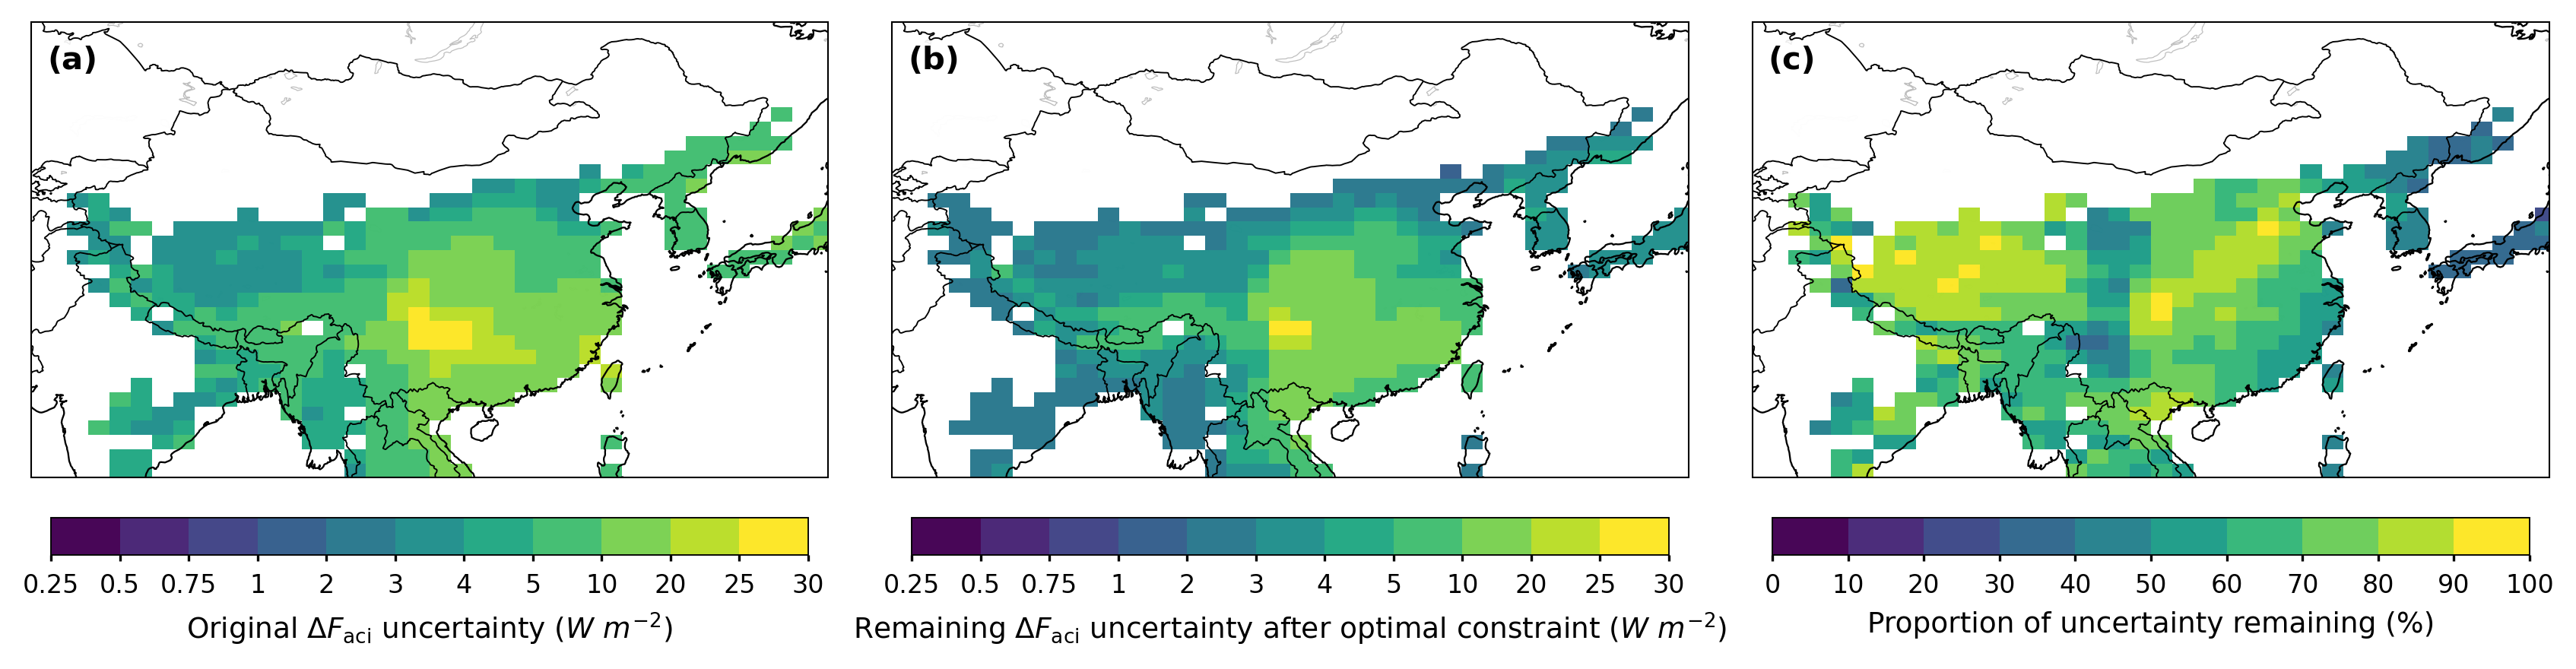

In [2]:
# ============================================================
# FACI uncertainty over China land N96 gridpoints
#
# Index usage:
#   完全学习你给的程序：
#       indices_decimal = np.loadtxt(index_file)
#       indices = np.array([int(i) for i in indices_decimal], dtype=int)
#   不减 1
#   不自动判断 R/Python index
#
# Plot style:
#   不使用等值线，不插值
#   直接使用 CSV 中的 N96 latitude / longitude
#   每个格点画成一个 square marker
#   风格接近 cluster map / Fig.2-style map
#
# Important:
#   只展示 full case uncertainty > 3 W m^-2 的格点
#   这对应 Fig.2 中 proportion remaining panel 对 original uncertainty < 3 的 mask 逻辑
#
# Output:
#   1. Notebook 直接显示图，不保存图片
#   2. 保存 summary CSV
#   3. 保存 NPZ
# ============================================================

import os
import glob
import warnings

import numpy as np
import pandas as pd

import matplotlib as mp
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm

import cartopy.crs as ccrs
import cartopy.feature as cfeature

try:
    from tqdm.notebook import tqdm
except Exception:
    from tqdm import tqdm


# ============================================================
# 1. 基础路径设置
# ============================================================

gpe_output_dir = "/gws/ssde/j25a/acure/jianxing/aci/emulation/data_post_emulation"

grid_index_file = "/home/users/jianxing/New_final/ACI_gridpoint_index.csv"

sample_file_norm_all = "/home/users/lregayre/R/ACURE/samples/constrained_multi_million_sample_first_million.dat"

filtered_indices_file = "/gws/ssde/j25a/acure/lregayre/constraint/indices_used_to_filter_898610_members_sample_for_prim_so4_diam.dat"

optimal_indices_file = "/home/users/jianxing/copy/optimal_constraint_13th_variable_indices_from_1M.dat"

out_dir = "/home/users/jianxing/New_final/land/Figure2_style/FACI_uncertainty_China_land"
os.makedirs(out_dir, exist_ok=True)

target_month = "ann"
sample_size_full = 1000000
pred_length_text = "1000000"

china_extent = [70, 140, 15, 55]

# 明确体现 Fig.2 里的 original uncertainty > 3 W m^-2 条件
full_uncertainty_threshold = 3.0


# ============================================================
# 2. 工具函数
# ============================================================

def detect_column(df, candidates, required=True):
    lower_to_original = {c.lower(): c for c in df.columns}

    for c in candidates:
        if c.lower() in lower_to_original:
            return lower_to_original[c.lower()]

    if required:
        raise ValueError(
            f"Cannot find any of columns {candidates}. "
            f"Available columns are: {list(df.columns)}"
        )

    return None


def format_cluster_for_filename(x):
    """
    文件名里需要 ACI_c1 / ACI_c5 / ACI_c7，
    不是 ACI_c1.0。
    """
    try:
        return str(int(float(x)))
    except Exception:
        return str(x).strip()


def read_grid_index_csv(grid_index_file):
    """
    只读取 CSV 中的信息。
    不转换经纬度，不排序，不重新筛选。
    """
    df = pd.read_csv(grid_index_file)

    cluster_col = detect_column(df, ["cluster"], required=True)
    lat_dir_col = detect_column(df, ["lat_dir"], required=True)
    lon_dir_col = detect_column(df, ["lon_dir"], required=True)
    lat_col = detect_column(df, ["latitude", "lat", "grid_latitude"], required=True)
    lon_col = detect_column(df, ["longitude", "lon", "grid_longitude"], required=True)

    df["_cluster_str"] = df[cluster_col].apply(format_cluster_for_filename)
    df["_lat_dir_use"] = df[lat_dir_col].astype(str).str.strip()
    df["_lon_dir_use"] = df[lon_dir_col].astype(str).str.strip()
    df["_latitude_use"] = df[lat_col].astype(float)
    df["_longitude_use"] = df[lon_col].astype(float)

    print("Grid index loaded:")
    print("  file:", grid_index_file)
    print("  n_rows:", len(df))
    print("  cluster column:", cluster_col)
    print("  lat_dir column:", lat_dir_col)
    print("  lon_dir column:", lon_dir_col)
    print("  latitude column:", lat_col)
    print("  longitude column:", lon_col)
    print("  latitude range:", df["_latitude_use"].min(), df["_latitude_use"].max())
    print("  longitude range:", df["_longitude_use"].min(), df["_longitude_use"].max())
    print("  clusters:", sorted(df["_cluster_str"].unique().tolist()))
    print("")

    return df


def read_indices_like_your_example(index_file, label):
    """
    完全学习你给的程序：

        indices_decimal = np.loadtxt(index_file)
        indices = [int(i) for i in indices_decimal]

    不减 1。
    不自动判断。
    """
    try:
        indices_decimal = np.loadtxt(index_file)
        indices = np.array([int(i) for i in np.ravel(indices_decimal)], dtype=int)

        print(f"{label} index loaded:")
        print(f"  file:", index_file)
        print(f"  n_index:", len(indices))
        print(f"  min index:", indices.min())
        print(f"  max index:", indices.max())
        print("")

        return indices

    except Exception as e:
        raise RuntimeError(f"Failed to load {label} indices from {index_file}: {e}")


def find_gpe_mean_file(constraint_text):
    """
    匹配你的 R 输出命名规则：

    emulated_mean_values_{constraint_text}_1000000_w_o_carb.dat
    """
    exact_file = os.path.join(
        gpe_output_dir,
        f"emulated_mean_values_{constraint_text}_{pred_length_text}_w_o_carb.dat"
    )

    if os.path.exists(exact_file):
        return exact_file, exact_file

    pattern = os.path.join(
        gpe_output_dir,
        f"emulated_mean_values_{constraint_text}_*_w_o_carb.dat"
    )

    matches = sorted(glob.glob(pattern))

    if len(matches) > 0:
        return matches[0], exact_file

    return None, exact_file


def calc_ci90_stats(values, indices=None):
    """
    计算 90% CI width:
        P95 - P5
    """
    values = np.asarray(values, dtype=float)

    if indices is None:
        data = values[:sample_size_full]
    else:
        indices = np.asarray(indices, dtype=int)

        # 这里不改 index，只检查是否越界
        if indices.min() < 0 or indices.max() >= len(values):
            raise IndexError(
                f"indices out of range for values length {len(values)}. "
                f"indices min/max = {indices.min()} / {indices.max()}"
            )

        data = values[indices]

    data = data[np.isfinite(data)]

    if len(data) == 0:
        return {
            "n": 0,
            "mean": np.nan,
            "p5": np.nan,
            "p95": np.nan,
            "ci90": np.nan,
        }

    p5, p95 = np.percentile(data, [5, 95])

    return {
        "n": int(len(data)),
        "mean": float(np.mean(data)),
        "p5": float(p5),
        "p95": float(p95),
        "ci90": float(p95 - p5),
    }


# ============================================================
# 3. 读取 CSV 和 index
# ============================================================

grid_df = read_grid_index_csv(grid_index_file)

filtered_indices = read_indices_like_your_example(
    filtered_indices_file,
    label="filtered"
)

optimal_indices = read_indices_like_your_example(
    optimal_indices_file,
    label="optimal"
)


# ============================================================
# 4. 逐个 CSV 格点读取 GPE 输出并计算 CI
# ============================================================

records = []

n_file_found = 0
n_file_missing = 0
n_processed = 0

for row_id, row in tqdm(
    grid_df.iterrows(),
    total=len(grid_df),
    desc="Processing CSV N96 gridpoints"
):
    cluster_str = row["_cluster_str"]
    lat_dir = row["_lat_dir_use"]
    lon_dir = row["_lon_dir_use"]

    latitude = float(row["_latitude_use"])
    longitude = float(row["_longitude_use"])

    constraint_text = f"{target_month}_ACI_c{cluster_str}_{lat_dir}_{lon_dir}"

    mean_file, expected_file = find_gpe_mean_file(constraint_text)

    base_record = {
        "row_id": row_id,
        "cluster": cluster_str,
        "latitude": latitude,
        "longitude": longitude,
        "lat_dir": lat_dir,
        "lon_dir": lon_dir,
        "constraint_text": constraint_text,
        "expected_file": expected_file,
    }

    if mean_file is None:
        n_file_missing += 1

        rec = dict(base_record)
        rec.update({
            "file_found": False,
            "mean_file": "",
            "error": "GPE mean file not found",
            "unc_full": np.nan,
            "unc_filtered": np.nan,
            "unc_optimal": np.nan,
            "remaining_pct": np.nan,
            "full_gt3": False,
            "mean_full": np.nan,
            "mean_filtered": np.nan,
            "mean_optimal": np.nan,
            "p5_full": np.nan,
            "p95_full": np.nan,
            "p5_filtered": np.nan,
            "p95_filtered": np.nan,
            "p5_optimal": np.nan,
            "p95_optimal": np.nan,
            "n_full": 0,
            "n_filtered": 0,
            "n_optimal": 0,
        })

        records.append(rec)
        continue

    n_file_found += 1

    try:
        values = np.loadtxt(mean_file)

        stats_full = calc_ci90_stats(values, indices=None)
        stats_filtered = calc_ci90_stats(values, indices=filtered_indices)
        stats_optimal = calc_ci90_stats(values, indices=optimal_indices)

        unc_full = stats_full["ci90"]
        unc_filtered = stats_filtered["ci90"]
        unc_optimal = stats_optimal["ci90"]

        if np.isfinite(unc_full) and unc_full > 0:
            remaining_pct = unc_optimal / unc_full * 100.0
        else:
            remaining_pct = np.nan

        full_gt3 = bool(np.isfinite(unc_full) and unc_full > full_uncertainty_threshold)

        rec = dict(base_record)
        rec.update({
            "file_found": True,
            "mean_file": mean_file,
            "error": "",
            "unc_full": unc_full,
            "unc_filtered": unc_filtered,
            "unc_optimal": unc_optimal,
            "remaining_pct": remaining_pct,
            "full_gt3": full_gt3,
            "mean_full": stats_full["mean"],
            "mean_filtered": stats_filtered["mean"],
            "mean_optimal": stats_optimal["mean"],
            "p5_full": stats_full["p5"],
            "p95_full": stats_full["p95"],
            "p5_filtered": stats_filtered["p5"],
            "p95_filtered": stats_filtered["p95"],
            "p5_optimal": stats_optimal["p5"],
            "p95_optimal": stats_optimal["p95"],
            "n_full": stats_full["n"],
            "n_filtered": stats_filtered["n"],
            "n_optimal": stats_optimal["n"],
        })

        records.append(rec)
        n_processed += 1

    except Exception as e:
        rec = dict(base_record)
        rec.update({
            "file_found": True,
            "mean_file": mean_file,
            "error": f"Failed to read/process file: {e}",
            "unc_full": np.nan,
            "unc_filtered": np.nan,
            "unc_optimal": np.nan,
            "remaining_pct": np.nan,
            "full_gt3": False,
            "mean_full": np.nan,
            "mean_filtered": np.nan,
            "mean_optimal": np.nan,
            "p5_full": np.nan,
            "p95_full": np.nan,
            "p5_filtered": np.nan,
            "p95_filtered": np.nan,
            "p5_optimal": np.nan,
            "p95_optimal": np.nan,
            "n_full": 0,
            "n_filtered": 0,
            "n_optimal": 0,
        })

        records.append(rec)


summary_df = pd.DataFrame(records)

print("")
print("Processing summary:")
print("  CSV rows:", len(grid_df))
print("  GPE files found:", n_file_found)
print("  GPE files missing:", n_file_missing)
print("  successfully processed:", n_processed)
print("  finite full:", int(np.isfinite(summary_df["unc_full"]).sum()))
print("  finite filtered:", int(np.isfinite(summary_df["unc_filtered"]).sum()))
print("  finite optimal:", int(np.isfinite(summary_df["unc_optimal"]).sum()))
print("  full > 3 W m^-2:", int(summary_df["full_gt3"].sum()))
print("")


# ============================================================
# 5. 保存两个文件
# ============================================================

out_csv = os.path.join(
    out_dir,
    f"FACI_uncertainty_China_land_{target_month}_gridpoint_summary_direct_csv_points.csv"
)

summary_df.to_csv(out_csv, index=False)

out_npz = os.path.join(
    out_dir,
    f"FACI_uncertainty_China_land_{target_month}_direct_csv_points.npz"
)

np.savez_compressed(
    out_npz,
    row_id=summary_df["row_id"].values,
    cluster=summary_df["cluster"].values,
    latitude=summary_df["latitude"].values,
    longitude=summary_df["longitude"].values,
    lat_dir=summary_df["lat_dir"].values,
    lon_dir=summary_df["lon_dir"].values,
    unc_full=summary_df["unc_full"].values,
    unc_filtered=summary_df["unc_filtered"].values,
    unc_optimal=summary_df["unc_optimal"].values,
    remaining_pct=summary_df["remaining_pct"].values,
    full_gt3=summary_df["full_gt3"].values,
    mean_full=summary_df["mean_full"].values,
    mean_filtered=summary_df["mean_filtered"].values,
    mean_optimal=summary_df["mean_optimal"].values,
    p5_full=summary_df["p5_full"].values,
    p95_full=summary_df["p95_full"].values,
    p5_filtered=summary_df["p5_filtered"].values,
    p95_filtered=summary_df["p95_filtered"].values,
    p5_optimal=summary_df["p5_optimal"].values,
    p95_optimal=summary_df["p95_optimal"].values,
)

print("Saved:")
print("  CSV:", out_csv)
print("  NPZ:", out_npz)
print("")

try:
    display(summary_df.head())
except Exception:
    print(summary_df.head())


# ============================================================
# 6. 画图：N96 gridbox / cluster 风格网格盒子图
# ============================================================

def centers_to_edges(centers):
    """
    根据 N96 网格中心点，计算网格边界。
    这一步不是插值，只是把中心点转换成 pcolormesh 需要的 cell edge。
    """
    centers = np.asarray(centers, dtype=float)
    centers = np.sort(np.unique(centers))

    if len(centers) == 1:
        delta = 1.0
        return np.array([centers[0] - delta / 2.0, centers[0] + delta / 2.0])

    midpoints = (centers[:-1] + centers[1:]) / 2.0

    first_edge = centers[0] - (midpoints[0] - centers[0])
    last_edge = centers[-1] + (centers[-1] - midpoints[-1])

    edges = np.concatenate([[first_edge], midpoints, [last_edge]])

    return edges


def make_pcolormesh_grid(plot_df, value_col):
    """
    将离散 N96 lon/lat/value 点整理成 pcolormesh 所需的 2D 网格。
    不插值。
    不填补缺失格点。
    不满足 full>3 或没有数据的位置保持 NaN，因此显示为白色背景。
    """
    grid = plot_df.pivot_table(
        index="latitude",
        columns="longitude",
        values=value_col,
        aggfunc="mean"
    )

    grid = grid.sort_index(axis=0)
    grid = grid.sort_index(axis=1)

    lat_centers = grid.index.values.astype(float)
    lon_centers = grid.columns.values.astype(float)

    lat_edges = centers_to_edges(lat_centers)
    lon_edges = centers_to_edges(lon_centers)

    values_2d = grid.values.astype(float)
    values_2d = np.ma.masked_invalid(values_2d)

    return lon_edges, lat_edges, values_2d


def plot_gridbox_fig2_cluster_style(
    summary_df,
    extent=(70, 140, 15, 55),
    marker_size=72,
    full_threshold=3.0,
):
    """
    画图方式：
      - 不使用等值线
      - 不插值
      - 直接使用 CSV 中的 lon/lat
      - 使用 pcolormesh 把每个 N96 格点画成真实 grid box
      - 只显示 full case uncertainty > 3 W m^-2 的格点

    当前图：
      (a) Original Delta F_aci uncertainty
      (b) Remaining Delta F_aci uncertainty after optimal constraint
      (c) Proportion of uncertainty remaining
    """

    plot_df_all = summary_df[
        (summary_df["file_found"] == True) &
        np.isfinite(summary_df["longitude"]) &
        np.isfinite(summary_df["latitude"]) &
        np.isfinite(summary_df["unc_full"]) &
        np.isfinite(summary_df["unc_optimal"]) &
        np.isfinite(summary_df["remaining_pct"])
    ].copy()

    plot_df = plot_df_all[plot_df_all["unc_full"] > full_threshold].copy()

    if len(plot_df) == 0:
        raise ValueError(
            f"No valid gridpoints with full uncertainty > {full_threshold} W m^-2."
        )

    print("Plotting summary:")
    print("  valid gridpoints before full>3 filter:", len(plot_df_all))
    print(f"  valid gridpoints after full>{full_threshold} filter:", len(plot_df))
    print("  longitude range:", plot_df["longitude"].min(), plot_df["longitude"].max())
    print("  latitude range:", plot_df["latitude"].min(), plot_df["latitude"].max())
    print("  full uncertainty range:", plot_df["unc_full"].min(), plot_df["unc_full"].max())
    print("  optimal uncertainty range:", plot_df["unc_optimal"].min(), plot_df["unc_optimal"].max())
    print("  remaining pct range:", plot_df["remaining_pct"].min(), plot_df["remaining_pct"].max())
    print("")

    # Fig_2.py 风格 levels，保持原来的 colorbar 分段色块
    levels_percentage = np.arange(11) * 10

    levels_variance = [
        0.25,
        0.5,
        0.75,
        1.0,
        2.0,
        3.0,
        4.0,
        5.0,
        10.0,
        20.0,
        25.0,
        30.0,
    ]

    levels_variance_tick_labels = [
        "0.25",
        "0.5",
        "0.75",
        "1",
        "2",
        "3",
        "4",
        "5",
        "10",
        "20",
        "25",
        "30",
    ]

    cmap_pos = plt.get_cmap("viridis").copy()
    cmap_pos2 = plt.get_cmap("viridis").copy()

    # NaN 区域透明，下面的白色地图底色会显示出来
    cmap_pos.set_bad(color="white", alpha=0.0)
    cmap_pos2.set_bad(color="white", alpha=0.0)

    norm_variance = BoundaryNorm(
        levels_variance,
        ncolors=cmap_pos.N,
        clip=True,
    )

    norm_percentage = BoundaryNorm(
        levels_percentage,
        ncolors=cmap_pos2.N,
        clip=True,
    )

    # ========================================================
    # ACP / Copernicus-compatible font settings
    # ========================================================

    mp.rcParams["font.family"] = "sans-serif"
    mp.rcParams["font.sans-serif"] = [
        "Arial",
        "Helvetica",
        "DejaVu Sans",
    ]

    font_size = 8

    mp.rcParams["axes.labelsize"] = font_size
    mp.rcParams["axes.linewidth"] = 0.5
    mp.rcParams["axes.titlesize"] = 9
    mp.rcParams["legend.fontsize"] = font_size
    mp.rcParams["xtick.labelsize"] = font_size
    mp.rcParams["ytick.labelsize"] = font_size

    DELTA = "\u0394"

    fontsize_legends = 8
    fontsize_text = 9
    fontsize_subtext = 10

    shrink_size = 0.95

    # ========================================================
    # 1 x 3 layout
    # ========================================================

    fig = plt.figure(
        figsize=(11.5, 4.2),
        dpi=300,
    )

    panel_info = [

        (
            "unc_full",
            "(a)",
            "Original "
            + DELTA
            + "$F_{\\mathrm{aci}}$ uncertainty ($W\\ m^{-2}$)",
            norm_variance,
            cmap_pos,
            levels_variance,
            levels_variance_tick_labels,
        ),

        (
            "unc_optimal",
            "(b)",
            "Remaining "
            + DELTA
            + "$F_{\\mathrm{aci}}$ uncertainty after optimal constraint ($W\\ m^{-2}$)",
            norm_variance,
            cmap_pos,
            levels_variance,
            levels_variance_tick_labels,
        ),

        (
            "remaining_pct",
            "(c)",
            "Proportion of uncertainty remaining (%)",
            norm_percentage,
            cmap_pos2,
            levels_percentage,
            None,
        ),
    ]

    for ipanel, (
        col,
        panel_label,
        cbar_label,
        norm,
        cmap,
        ticks,
        ticklabels,
    ) in enumerate(
        panel_info,
        start=1,
    ):

        ax = fig.add_subplot(
            1,
            3,
            ipanel,
            projection=ccrs.PlateCarree(),
        )

        ax.set_extent(
            extent,
            crs=ccrs.PlateCarree(),
        )

        # 白色底图：除有色网格盒子之外，其余地方全部白色
        ax.set_facecolor("white")

        ax.add_feature(
            cfeature.LAND,
            facecolor="white",
            edgecolor="none",
            zorder=0,
        )

        ax.add_feature(
            cfeature.OCEAN,
            facecolor="white",
            edgecolor="none",
            zorder=0,
        )

        ax.add_feature(
            cfeature.LAKES,
            facecolor="white",
            edgecolor="0.75",
            linewidth=0.3,
            zorder=1,
        )

        ax.coastlines(
            resolution="50m",
            linewidth=0.55,
            color="black",
            zorder=3,
        )

        ax.add_feature(
            cfeature.BORDERS,
            linewidth=0.45,
            edgecolor="black",
            zorder=3,
        )

        # pcolormesh：不插值，只把已有 N96 中心点转换成真实网格盒子
        lon_edges, lat_edges, values_2d = make_pcolormesh_grid(
            plot_df,
            col,
        )

        pc = ax.pcolormesh(
            lon_edges,
            lat_edges,
            values_2d,
            cmap=cmap,
            norm=norm,
            transform=ccrs.PlateCarree(),
            shading="flat",
            edgecolors="none",
            linewidth=0.0,
            alpha=0.98,
            zorder=2,
        )

        # panel label
        ax.text(
            0.02,
            0.95,
            panel_label,
            transform=ax.transAxes,
            fontsize=fontsize_subtext,
            fontweight="bold",
            va="top",
            ha="left",
            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.70,
                pad=1.5,
            ),
            zorder=5,
        )

        # 不画经纬网虚线

        cbar = plt.colorbar(
            pc,
            ax=ax,
            ticks=ticks,
            shrink=shrink_size,
            orientation="horizontal",
            pad=0.05,
            use_gridspec=True,
        )

        cbar.ax.set_xlabel(
            cbar_label,
            fontsize=fontsize_text,
        )

        cbar.ax.tick_params(
            labelsize=fontsize_legends,
            length=2,
        )

        if ticklabels is not None:
            cbar.set_ticklabels(
                ticklabels
            )

        cbar.outline.set_linewidth(
            0.45
        )

    # fig.suptitle(
    #     f"China land grid boxes with original {DELTA}$F_{{\\mathrm{{aci}}}}$ uncertainty > {full_threshold} W m$^{{-2}}$",
    #     fontsize=12,
    #     y=0.995,
    # )

    plt.subplots_adjust(
        left=0.025,
        right=0.985,
        top=0.95,
        bottom=0.12,
        wspace=0.08,
    )

    plt.show()


plot_gridbox_fig2_cluster_style(
    summary_df,
    extent=china_extent,
    marker_size=72,
    full_threshold=full_uncertainty_threshold,
)